# Benchmark AlphaFold3 against sequence models

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences_100_unbalanced = pd.read_csv('../data/interim/sequences_sample_100_unbalanced.csv', index_col='index')
sequences_100_unbalanced.index = sequences_100_unbalanced.index.astype(str)

In [4]:
confidences_100_unbalanced = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_100_unbalanced.csv')
confidences_100_unbalanced['name'] = confidences_100_unbalanced['name'].astype(str)

confidences_100_unbalanced = confidences_100_unbalanced.loc[
    confidences_100_unbalanced.groupby('name')['ranking_score'].idxmax()
]

In [5]:
confidences_100_unbalanced = confidences_100_unbalanced.merge(
    sequences_100_unbalanced, how='left', left_on='name', right_index=True
)

In [6]:
tcr_struct_map_predictions = pd.read_csv('../data/external/TCRStructMap_predictions_on_sequences_pMHC_split.csv')
tcr_struct_map_predictions['index'] = tcr_struct_map_predictions['index'].astype(str)

In [7]:
tcr_struct_map_predictions_100_unbalanced = tcr_struct_map_predictions.merge(
    sequences_100_unbalanced, how='right', left_on='index', right_index=True
).query('sub_model_number == fold')
tcr_struct_map_predictions_100_unbalanced = tcr_struct_map_predictions_100_unbalanced.set_index('index')

In [8]:
nettcr_predictions = pd.read_csv('../data/external/NetTCR_predictions_on_sequences_pMHC_split.csv')
nettcr_predictions['index'] = nettcr_predictions['index'].astype(str)

In [9]:
nettcr_predictions_100_unbalanced = nettcr_predictions.merge(
    sequences_100_unbalanced, how='right', left_on='index', right_index=True
).query('sub_model_number == fold')
nettcr_predictions_100_unbalanced = nettcr_predictions_100_unbalanced.set_index('index')

In [10]:
def calculate_performance(predictions: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = roc_auc_score(labels, predictions)
    roc_auc01 = roc_auc_score(labels, predictions, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, predictions)
    pr_auc = auc(recall, precision)

    return {'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc}


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [11]:
metric_scores = {
    'model': [],
    'roc_auc': [],
    'roc_auc_01': [],
    'pr_auc': [],
}
# AlphaFold3
metric_scores['model'].append('AlphaFold3')

scores = calculate_performance(confidences_100_unbalanced['cdr_pmhc_pae_score'], confidences_100_unbalanced['label'])
for name, score in scores.items():
    metric_scores[name].append(1 - score)

# NetTCR
metric_scores['model'].append('NetTCR')

scores = calculate_performance(
    nettcr_predictions_100_unbalanced['prediction'], nettcr_predictions_100_unbalanced['label']
)
for name, score in scores.items():
    metric_scores[name].append(score)

# TCRStructMap
metric_scores['model'].append('TCRStructMap')

scores = calculate_performance(
    tcr_struct_map_predictions_100_unbalanced['prediction'],
    tcr_struct_map_predictions_100_unbalanced['label'],
)
for name, score in scores.items():
    metric_scores[name].append(score)

metric_scores = pd.DataFrame(metric_scores).set_index('model')
metric_scores

,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold3,0.6420,0.498947,0.546761
NetTCR,0.4428,0.484211,0.446498
TCRStructMap,0.4424,0.488421,0.457537


In [12]:
NUM_SAMPLES = 20
SAMPLE_SIZE = 50

rng = np.random.default_rng(123)

boot_strap_scores = {
    'sample_num': [],
    'model': [],
    'roc_auc': [],
    'roc_auc_01': [],
    'pr_auc': [],
}
for sample_num in range(NUM_SAMPLES):
    indices = sequences_100_unbalanced.sample(SAMPLE_SIZE, random_state=rng).index

    # AlphaFold3
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('AlphaFold3')

    scores = calculate_performance(
        confidences_100_unbalanced[confidences_100_unbalanced['name'].isin(indices)]['cdr_pmhc_pae_score'],
        confidences_100_unbalanced[confidences_100_unbalanced['name'].isin(indices)]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(1 - score)

    # NetTCR
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('NetTCR')

    scores = calculate_performance(
        nettcr_predictions_100_unbalanced.loc[indices]['prediction'],
        nettcr_predictions_100_unbalanced.loc[indices]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(score)

    # TCRStructMap
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('TCRStructMap')

    scores = calculate_performance(
        tcr_struct_map_predictions_100_unbalanced.loc[indices]['prediction'],
        tcr_struct_map_predictions_100_unbalanced.loc[indices]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(score)

boot_strap_scores = pd.DataFrame(boot_strap_scores)

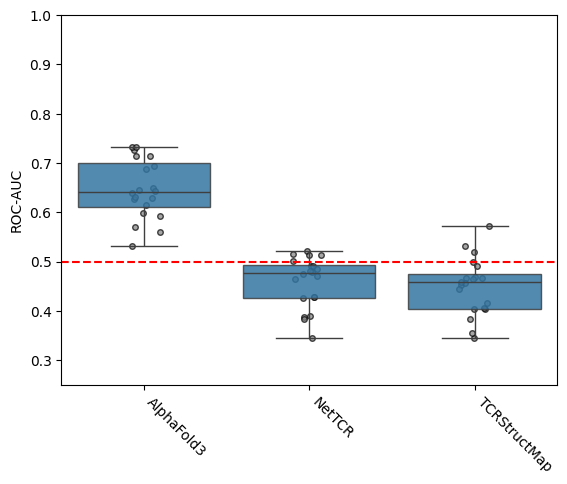

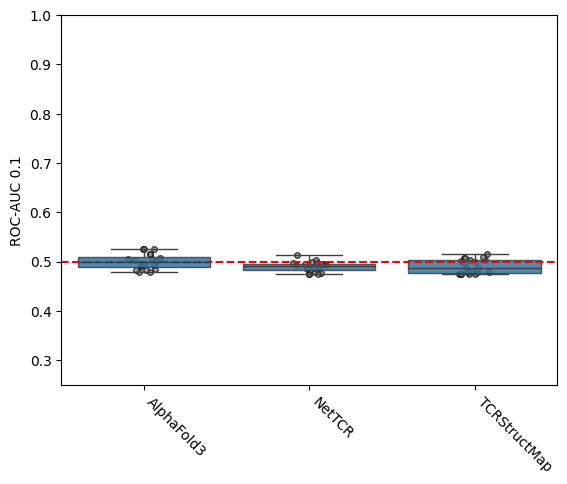

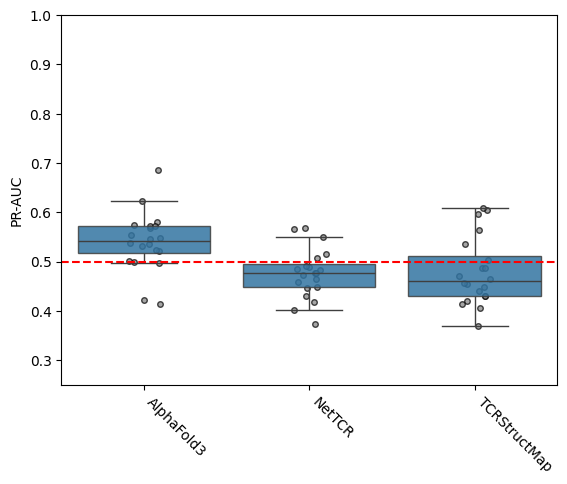

In [13]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    ax = sns.stripplot(
        boot_strap_scores,
        x='model',
        y=metric_name,
        color='grey',
        zorder=1,
        marker='o',
        size=4,
        edgecolor='black',
        linewidth=1,
        alpha=0.70,
    )

    sns.boxplot(boot_strap_scores, x='model', y=metric_name, boxprops={'alpha': 0.85}, showfliers=False)

    ax.axhline(0.5, color='r', linestyle='dashed')

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), rotation=-45, horizontalalignment='left')

    ax.set_xlabel('')
    ax.set_ylim(0.25, 1.0)

    ax.set_ylabel(format_metric_name(metric_name))

    plt.show()

In [14]:
norm_val = stats.norm.ppf(1 - SIGNIFICANCE_LEVEL / 2)

scores_agg = metric_scores.join(boot_strap_scores.set_index('sample_num').groupby('model').agg('std'), rsuffix='_std')
for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    scores_agg[f'{metric}_ci'] = scores_agg.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[metric] - norm_val * row[f'{metric}_std'],
            row[metric] + norm_val * row[f'{metric}_std'],
        ),
        axis=1,
    )

scores_agg

,roc_auc,roc_auc_01,pr_auc,roc_auc_std,roc_auc_01_std,pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
model,,,,,,,,,
AlphaFold3,0.6420,0.498947,0.546761,0.059717,0.015679,0.060654,"(0.524955994390491, 0.7590440056095092)","(0.4682168360104485, 0.5296779008316567)","(0.42788075102644063, 0.6656411638861408)"
NetTCR,0.4428,0.484211,0.446498,0.051465,0.010780,0.050854,"(0.34192975423783745, 0.5436702457621626)","(0.46308186781256333, 0.5053391848190156)","(0.3468255626872989, 0.5461709919216636)"
TCRStructMap,0.4424,0.488421,0.457537,0.057947,0.014616,0.069322,"(0.32882611555807606, 0.5559738844419239)","(0.4597742316836302, 0.5170678735795277)","(0.3216687800874124, 0.5934056970338752)"


In [15]:
def calculate_differences(sample_groups: pd.DataFrame) -> pd.DataFrame:
    groups = list(sample_groups.groupby('model'))

    differences = {
        'group_name_i': [],
        'group_name_j': [],
        'difference_roc_auc': [],
        'difference_roc_auc_01': [],
        'difference_pr_auc': [],
    }

    for i, (group_name_i, group_i) in enumerate(groups):
        for group_name_j, group_j in groups[i + 1 :]:
            for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
                difference = group_i[metric].iloc[0] - group_j[metric].iloc[0]
                differences[f'difference_{metric}'].append(difference)

            differences['group_name_i'].append(group_name_i)
            differences['group_name_j'].append(group_name_j)

    return pd.DataFrame(differences)

In [16]:
norm_val = stats.norm.ppf(1 - SIGNIFICANCE_LEVEL / 2)

metric_scores_differences = calculate_differences(metric_scores)
samples_metric_scores_differences = (
    boot_strap_scores.groupby('sample_num')
    .apply(calculate_differences, include_groups=False)
    .groupby(['group_name_i', 'group_name_j'])
    .agg(['std'])
)
samples_metric_scores_differences.columns = ['_'.join(column) for column in samples_metric_scores_differences.columns]
samples_metric_scores_differences = samples_metric_scores_differences.reset_index()

metric_scores_differences = metric_scores_differences.merge(samples_metric_scores_differences)

for metric in 'roc_auc', 'roc_auc_01', 'pr_auc':
    metric_scores_differences[f'{metric}_ci'] = metric_scores_differences.apply(
        lambda row, metric=metric, norm_val=norm_val: (
            row[f'difference_{metric}'] - norm_val * row[f'difference_{metric}_std'],
            row[f'difference_{metric}'] + norm_val * row[f'difference_{metric}_std'],
        ),
        axis=1,
    )

metric_scores_differences

,group_name_i,group_name_j,difference_roc_auc,difference_roc_auc_01,difference_pr_auc,difference_roc_auc_std,difference_roc_auc_01_std,difference_pr_auc_std,roc_auc_ci,roc_auc_01_ci,pr_auc_ci
0,AlphaFold3,NetTCR,0.1992,0.014737,0.100263,0.079890,0.021438,0.100764,"(0.04261860621235963, 0.35578139378764057)","(-0.0272802414918632, 0.05675392570238941)","(-0.09723106164337209, 0.297756421946991)"
1,AlphaFold3,TCRStructMap,0.1996,0.010526,0.089224,0.097958,0.020712,0.118258,"(0.007605345530088459, 0.3915946544699119)","(-0.030069271245940395, 0.05112190282488772)","(-0.14255856138933115, 0.32100599918062495)"
2,NetTCR,TCRStructMap,0.0004,-0.004211,-0.011039,0.033924,0.017849,0.039302,"(-0.06608984464118615, 0.06688984464118629)","(-0.03919431737935041, 0.030773264747771527)","(-0.08807042741075595, 0.06599250489843085)"


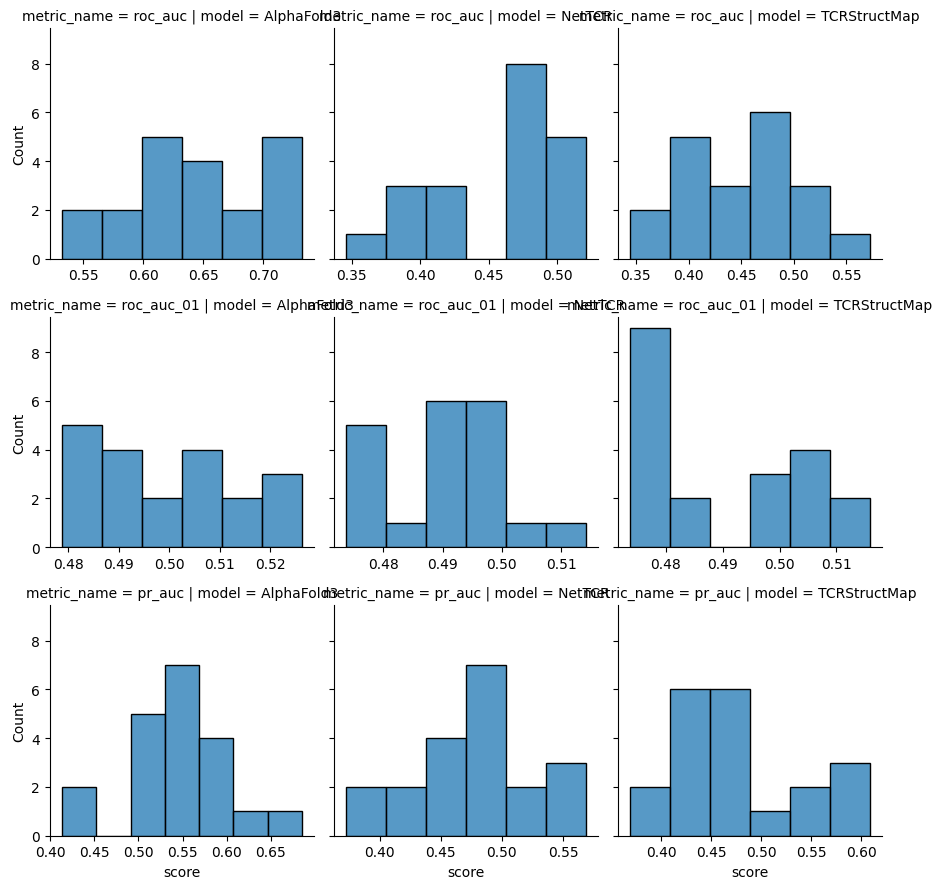

In [17]:
sns.FacetGrid(
    boot_strap_scores.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [18]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.rm_anova(data, dv=metric_name, within='model', subject='sample_num')

    groups = list(data.groupby('model', dropna=False)[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_rel(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [19]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    overall, post_hoc = statistics_normal(boot_strap_scores, metric_name)

    ipy_display.display(overall)
    ipy_display.display(post_hoc)
    print()

ROC-AUC


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,86.3368,7.367093e-15,0.730481,0.573694


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,10.492115,2.414214e-09,True
1,AlphaFold3,TCRStructMap,8.984077,2.870748e-08,True
2,NetTCR,TCRStructMap,1.233643,2.323796e-01,False



ROC-AUC 0.1


/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/pingouin/distribution.py:1004: RuntimeWarning: divide by zero encountered in scalar divide
  W = np.prod(eig) / (eig.sum() / d) ** d


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,3.509605,0.039933,0.114351,0.956672


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,2.212537,0.039372,False
1,AlphaFold3,TCRStructMap,2.147360,0.044881,False
2,NetTCR,TCRStructMap,-0.165533,0.870273,False



PR-AUC


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,6.157832,0.004825,0.200401,0.57522


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,2.861613,0.009985,True
1,AlphaFold3,TCRStructMap,2.312492,0.032119,False
2,NetTCR,TCRStructMap,-0.378493,0.709260,False
